In [ ]:
#1. 정답 라벨명이 있는 CSV 파일 불러오기
import pandas as pd
df= pd.read_csv('/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/dog-breed-identification/labels.csv')
print(df.head())
print(len(df))
print("품종 개수:", df['breed'].nunique())

                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever
10222
품종 개수: 120


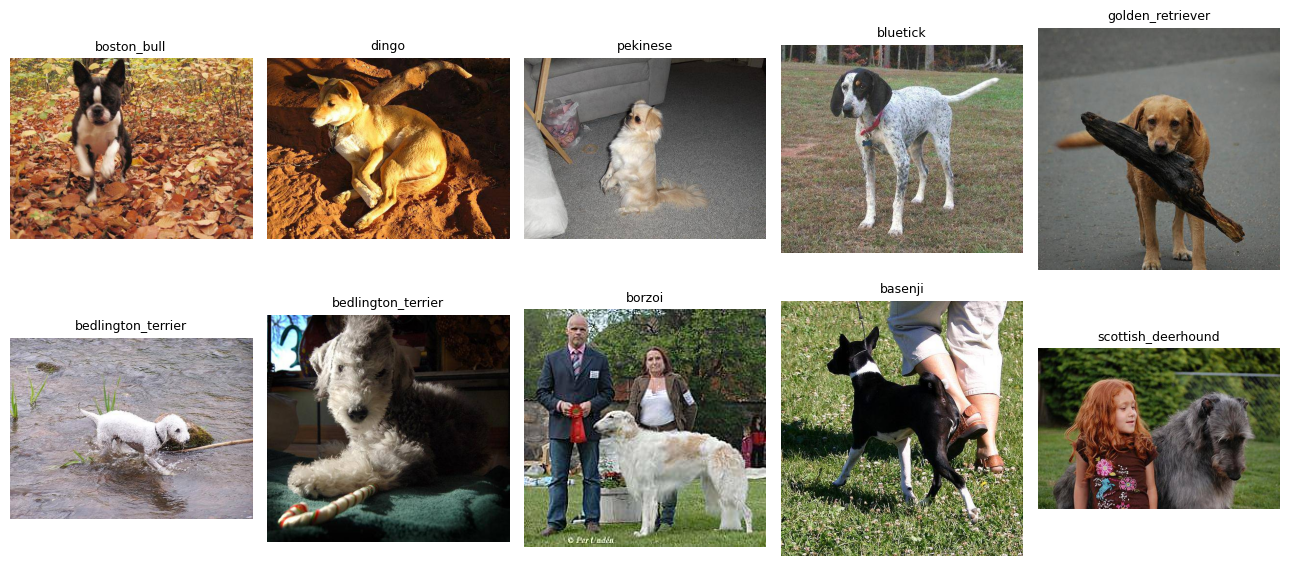

In [ ]:
# 이미지 시각화 (데이터셋 중에 앞 10개)
import matplotlib.pyplot as plt
from PIL import Image

# 2행 5열로 이미지를 보여줄 서브플롯들 준비
fig, axes= plt.subplots(2, 5, figsize=(13,6))

# 2행 5열을 1차원 10개로 만들어 반복하기
for i, ax in enumerate(axes.flat):   # i : 0~9
  # 현재번째 행(row)의 이미지 가져오기
  row= df.iloc[i]

  # row에 있는 id 정보를 이용하여 이미지 파일경로 준비
  image_path= f"/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/dog-breed-identification/train/{row['id']}.jpg"
  image= Image.open(image_path)

  # 그래프 영역에 이미지를 그리고, 품종도 표시하기
  ax.imshow(image)
  ax.set_title( row['breed'], fontsize=9 )
  ax.axis('off')
#------------------------------------------------
plt.tight_layout()
plt.show()

In [ ]:
# 학습할 데이터 준비
# 이미지 전처리도 해야하기에, 전이학습에 사용할 모델이 학습할때 사용한 전처리를 그대로 활용
import torch
from torchvision import models

#1) 사전학습된 모델의 가중치가 권장하는 전처리 정보
weight= models.ResNet152_Weights.DEFAULT
transform= weight.transforms()  # resnet152 모델이 학습할때 사용한 전처리객체를 얻어올 수 있음.

In [ ]:
#2) CSV를 이용한 Dataset 만들기 -- 커스텀 데이터셋 클래스 정의
from torch.utils.data import Dataset  # 이 클래스를 상속해서 커스텀 데이터셋 정의

# 품종 이름을 숫자로 변환 (딥러닝의 다중분류의 종속변수(결과) 라벨값은 0,1,2,... 정수형으로 학습)
class_names= sorted(df['breed'].unique())
print(len(class_names))
class_to_idx= {name:i for i, name in enumerate(class_names)}   # {'말티즈':0, '포메':1, ... }

class DogDataset(Dataset):
  def __init__(self, dataframe, transform):  #파일명과 라벨명 정보를 가진 데이터프레임, 전처리객체
    #학습에 너무 오래 걸려서 전체 이미지 중 10%만 훈련.
    dataframe= dataframe.head( int(dataframe.shape[0]*0.1) )

    self.df= dataframe.reset_index(drop=True)  #인덱스번호를 다시 0부터.
    self.transform= transform
  #--------------

  #제공할 데이터의 총 개수를 알려주는 기능함수
  def __len__(self):
    return len(self.df)

  # 이 클래스가 학습하도록 제공할 데이터(이미지픽셀들, 라벨번호)를 리턴해주는 기능함수
  def __getitem__(self, idx):
    #파라미터로 전달받은 이미지 인덱스 번호에 해당하는 이미지파일경로, 라벨명 정도 받기
    row= self.df.iloc[idx]

    #해당 이미지의 파일명(id)을 기반으로 이미지객체(배열덩어리) 만들기
    image_path= f"/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/dog-breed-identification/train/{row['id']}.jpg"
    image= Image.open(image_path).convert('RGB')

    #이미지를 학습에 어울리게 전처리
    image= self.transform(image)

    #종속변수는 글씨면 학습이 안되기에 숫자로 변환
    label= class_to_idx[row['breed']]

    #독립변수: 이미지배열 덩어리(image)
    #종속변수: 품종분류 번호(label)
    return image, label

120


In [ ]:
#3) 훈련용(train) 80%, 검증용(val) 10%, 테스트용(test) 10% 로 분리
from sklearn.model_selection import train_test_split

#먼저, 훈련용과 나머지로 분리
train_df, temp_df= train_test_split(df, test_size=0.2, stratify=df['breed'], random_state=42)

#나머지를 다시 반반으로 분리(검증용, 테스트용)
val_df, test_df= train_test_split(temp_df, test_size=0.5, stratify=temp_df['breed'], random_state=42)

In [ ]:
#4) 분리된 데이터프레임을 모델이 학습할 수 있는 데이터셋 형식으로 만들기
train_dataset= DogDataset(train_df, transform)
val_dataset= DogDataset(val_df, transform)
test_dataset= DogDataset(test_df, transform)

In [ ]:
#5) torch 모델이 미니배치 단위로 학습하기 용이하도록 DataLoader 생성
from torch.utils.data import DataLoader
train_loader= DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader= DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader= DataLoader(test_dataset, batch_size=16, shuffle=False)

print(len(train_loader), len(val_loader), len(test_loader))

52 7 7


In [ ]:
# 사전학습된 pre-trained model 준비
model= models.resnet152(weights=weight)

In [ ]:
# 사전학습모델의 마지막 분류층을 확인해보기
print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


In [ ]:
#마지막 분류기의 출력층을 내가 원하는 분류개수로 바꿔치기!(전이학습)
import torch.nn as nn
model.fc= nn.Linear(model.fc.in_features, 120)
print(model.fc)

Linear(in_features=2048, out_features=120, bias=True)


In [ ]:
# GPU가 가능한 환경이라면 GPU로 모델을 이동
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model= model.to(device)
model

cpu


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
# 모델을 학습하기 전에 기존 가중치는 고정
for param in model.parameters():
  param.requires_grad= False

# 마지막 FC 레이어만 학습하도록
for param in model.fc.parameters():
  param.requires_grad= True

In [ ]:
# 학습할때 필요한 2개의 구성요소 (손실함수, 최적화)
criterion= nn.CrossEntropyLoss()  #다중분류의 손실함수
optimizer= torch.optim.Adam(model.fc.parameters(), lr=0.001)

In [ ]:
# 모델 학습
# 반복횟수 .. 실습이니까 1번만... 현업에서 1회학습은 Never...
epochs= 1

for epoch in range(epochs):
  #전이학습에서는 conv layer를 건드리지 않기에, dropout같은 작업을 하지 않음.
  #그래서 굳이 학습모드 말고 평가모드로 실행
  model.eval()

  # 현재 몇개의 이미지를 학습했는지 카운트용 변수
  total=0

  # 미니배치(16장) 단위로 학습
  for images, labels in train_loader:
    # GPU가 된다면 이미지와 라벨도 GPU vRAM으로 이동
    images= images.to(device)
    labels= labels.to(device)

    optimizer.zero_grad()
    outputs= model(images)
    loss= criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    total += labels.size(0) #16
    print(f'current total: {total} // 손실값: {loss.item()}')

current total: 16 // 손실값: 4.802146911621094
current total: 32 // 손실값: 4.782467365264893
current total: 48 // 손실값: 4.754416465759277
current total: 64 // 손실값: 4.615927219390869
current total: 80 // 손실값: 4.692312240600586
current total: 96 // 손실값: 4.800484657287598
current total: 112 // 손실값: 4.745246887207031
current total: 128 // 손실값: 4.685651779174805
current total: 144 // 손실값: 4.913731098175049
current total: 160 // 손실값: 4.817221641540527
current total: 176 // 손실값: 4.528674125671387
current total: 192 // 손실값: 4.644626617431641
current total: 208 // 손실값: 4.604523658752441
current total: 224 // 손실값: 4.696981430053711
current total: 240 // 손실값: 4.66508674621582
current total: 256 // 손실값: 4.398245811462402
current total: 272 // 손실값: 4.624937057495117
current total: 288 // 손실값: 4.731677055358887
current total: 304 // 손실값: 4.394877910614014
current total: 320 // 손실값: 4.540537357330322
current total: 336 // 손실값: 4.413675785064697
current total: 352 // 손실값: 4.486412048339844
current total: 36

In [ ]:
# 성능평가 -- 정확도, 재현율, 정밀도
# 테스트용 데이터셋으로 평가 진행
model.eval()

test_loss=0  #평균 손실값
correct= 0   #맞춘 개수
total=0

# 정밀도, 재현율 계산을 위한 변수
y_true= []   #정답값을 저장할 리스트
y_pred= []   #예측값을 저장할 리스트

with torch.no_grad():
  for images, labels in test_loader:
    images= images.to(device)
    labels= labels.to(device)

    outputs= model(images)
    loss= criterion(outputs, labels)

    #예측 분류번호
    predictions= outputs.argmax(dim=1)  #행단위로 가장 큰 값을 가진 인덱스 번호

    test_loss += loss.item() * images.size(0)  #모든 이미지의 손실값 누적
    correct += (predictions==labels).sum().item()  #맞춘 개수
    total += labels.size(0)
    print(total, correct)

    #정밀도, 재현율 같은 계산을 위해 실제값과 예측값을 보관...
    y_true.extend(labels.cpu().tolist())
    y_pred.extend(predictions.cpu().tolist())
#-------------------------------
print(f"TEST LOSS: {test_loss / total : .4f}")
print(f"TEST ACCURACY: { 100*correct / total : .2f}%")

16 5
32 11
48 17
64 24
80 32
96 38
102 41
TEST LOSS:  3.6824
TEST ACCURACY:  40.20%


In [ ]:
# 정밀도, 재현율 같은 분류 성능지표
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=class_names, labels=range(len(class_names))))

                                precision    recall  f1-score   support

                 affenpinscher       1.00      1.00      1.00         2
                  afghan_hound       1.00      1.00      1.00         1
           african_hunting_dog       0.00      0.00      0.00         0
                      airedale       1.00      1.00      1.00         2
american_staffordshire_terrier       0.00      0.00      0.00         0
                   appenzeller       0.00      0.00      0.00         0
            australian_terrier       0.00      0.00      0.00         0
                       basenji       1.00      1.00      1.00         1
                        basset       0.00      0.00      0.00         2
                        beagle       1.00      1.00      1.00         3
            bedlington_terrier       0.00      0.00      0.00         0
          bernese_mountain_dog       0.00      0.00      0.00         1
       black-and-tan_coonhound       0.00      0.00      0.00  

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/me

In [ ]:
# 새로운 이미지를 주고 모델에게 분류 요청해보기

# 새로운 이미지도 모델에 맞게 전처리 해야하므로..
transform= weight.transforms()

# 새로운 이미지의 경로 준비 (말티즈)
image_path= "/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/dog1.jpg"
image= Image.open(image_path).convert('RGB')
image= transform(image).unsqueeze(0).to(device)  # unsqueeze(): 3차원-->4차원 [c,h,w]-->[b,c,h,w]
#모델의 훈련데이터는 4차원 텐서 [배치사이즈, 채널, 높이, 너비]--[16,3,224,224]

In [21]:
#품종 예측
with torch.no_grad():
  outputs= model(image)
  probabilites= torch.softmax(outputs, dim=1)
  confidence, predicted= probabilites.max(dim=1)

In [22]:
#결과 출력
print('예측 클래스 번호:', predicted.item())
print('예측확률:', confidence.item() * 100)
print('예측 품종명:', class_names[predicted.item()])

예측 클래스 번호: 73
예측확률: 18.53407621383667
예측 품종명: maltese_dog


In [ ]:
# 모델을 저장할때는.. 모델객체를 통으로 저장하는 것보다는
# 모델에 필요한 가중치 등 파라미터값들만 저장한 후 불러서 사용하는 것을 권장
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names
}, "/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Models/dog-breed-model.pth")